## Step 0 — Setup, imports, and data loading

In [1]:
!pip install lifelines

In [2]:
# %% [0] Setup: imports and data loading

# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# Survival analysis
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test

# Optional: stats / preprocessing
from scipy import stats

# Display settings
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11
})

# Paths (adjust if needed)
BASE_DIR = Path(r"C:\Users\El-Wattaneya\brca_cleaned_outputs")
DATA_PATH = BASE_DIR / "analysis_ready_complete.csv"

print("Loading dataset from:", DATA_PATH)

# Load data
df = pd.read_csv(DATA_PATH, low_memory=False)

# Basic inspection
print("\nDataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nPreview:")
print(df.head().to_string(index=False))

Loading dataset from: C:\Users\El-Wattaneya\brca_cleaned_outputs\analysis_ready_complete.csv

Dataset shape: (1095, 28)

Columns:
['bcr_patient_barcode', 'event', 'survival_time_days', 'age_at_diagnosis_years', 'gender', 'race', 'ethnicity', 'menopause_status', 'stage_group', 'histological_type', 'er_status_by_ihc', 'pr_status_by_ihc', 'her2_status_by_ihc', 'received_radiation_record', 'received_drug_record', 'radiation_record_count', 'radiation_course_count', 'drug_record_count', 'unique_drug_count', 'unique_therapy_type_count', 'race_was_missing', 'ethnicity_was_missing', 'menopause_status_was_missing', 'stage_group_was_missing', 'histological_type_was_missing', 'er_status_by_ihc_was_missing', 'pr_status_by_ihc_was_missing', 'her2_status_by_ihc_was_missing']

Preview:
bcr_patient_barcode  event  survival_time_days  age_at_diagnosis_years gender                      race              ethnicity                                                                             menopause_status

## Step 1 — Basic validation

In [3]:
# %% [1] Basic validation

# Check duplicates
if "bcr_patient_barcode" in df.columns:
    print("Duplicate patient IDs:", df["bcr_patient_barcode"].duplicated().sum())

# Check outcome
print("\nEvent distribution:")
print(df["event"].value_counts(dropna=False))

print("\nMissing survival time:", df["survival_time_days"].isna().sum())

# Ensure correct types
df["event"] = pd.to_numeric(df["event"], errors="coerce").astype(int)
df["survival_time_days"] = pd.to_numeric(df["survival_time_days"], errors="coerce")

# Drop any problematic rows (should be minimal)
df = df.dropna(subset=["survival_time_days", "event"]).copy()

print("\nCleaned dataset shape:", df.shape)

Duplicate patient IDs: 0

Event distribution:
event
0    955
1    140
Name: count, dtype: int64

Missing survival time: 0

Cleaned dataset shape: (1095, 28)


## Step 2 — Fix multicollinearity

**We detected during EDA**

In [4]:
# %% [2] Fix multicollinearity (drug variables)

print("Columns before reduction:", df.shape[1])

# Drop redundant drug variables
drop_cols = [
    "unique_drug_count",
    "unique_therapy_type_count"
]

drop_cols = [c for c in drop_cols if c in df.columns]

if drop_cols:
    print("Dropping columns due to multicollinearity:", drop_cols)
    df = df.drop(columns=drop_cols)

print("Columns after reduction:", df.shape[1])

Columns before reduction: 28
Dropping columns due to multicollinearity: ['unique_drug_count', 'unique_therapy_type_count']
Columns after reduction: 26


## Step 3 — Simplify histological type

In [5]:
# %% [3] Simplify histological type (optional but recommended)

if "histological_type" in df.columns:
    counts = df["histological_type"].value_counts()

    # Keep top 2–3 categories, group the rest
    top_categories = counts.nlargest(3).index

    df["histological_type_simplified"] = np.where(
        df["histological_type"].isin(top_categories),
        df["histological_type"],
        "Other"
    )

    print("\nHistological type simplified:")
    print(df["histological_type_simplified"].value_counts())


Histological type simplified:
histological_type_simplified
Infiltrating Ductal Carcinoma     784
Infiltrating Lobular Carcinoma    203
Other                              62
Other, specify                     46
Name: count, dtype: int64


## Question 1: Does tumor stage significantly affect survival probability?

- Kaplan–Meier curves (visual comparison)
- Log-rank test (statistical test)
- Cox model (effect size via hazard ratios)

Stage distribution:
stage_group
Stage II     620
Stage III    248
Stage I      183
Stage IV      20
Name: count, dtype: int64


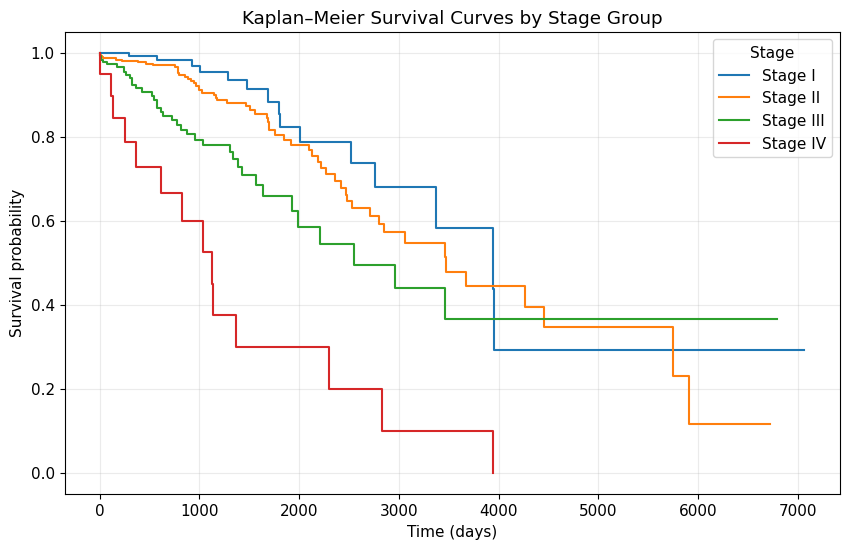


Log-rank test results:
   test_statistic             p   -log2(p)
0       53.338221  1.552875e-11  35.906267

Cox model results:


<lifelines.CoxPHFitter: fitted with 1071 total observations, 942 right-censored observations>
             duration col = 'survival_time_days'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1071
number of events observed = 129
   partial log-likelihood = -672.12
         time fit was run = 2026-04-18 15:45:45 UTC

---
                        coef  exp(coef)   se(coef)   coef lower 95%   coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%
covariate                                                                                                                     
stage_group_Stage II    0.41       1.51       0.29            -0.15             0.98                 0.86                 2.65
stage_group_Stage III   1.03       2.79       0.30             0.43             1.62                 1.54                 5.06
stage_group_Stage IV    2.11       8.25       0.37             1.38             2.84                 3.97                17.12

                        cmp to    z      p   -log2(p)
covariate                                            
stage_group_Stage II      0.00 1.42   0.15       2.70
stage_group_Stage III     0.00 3.37 <0.005      10.39
stage_group_Stage IV      0.00 5.66 <0.005      26.00
---
Concordance = 0.68
Partial AIC = 1350.24
log-likelihood ratio test = 35.54 on 3 df
-log2(p) of ll-ratio test = 23.35

In [6]:
# %% Question 1 — Stage and survival

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test
import matplotlib.pyplot as plt
import pandas as pd

# Copy dataset
df_stage = df.copy()

# Keep only valid stage groups (exclude Unknown)
stage_order = ["Stage I", "Stage II", "Stage III", "Stage IV"]
df_stage = df_stage[df_stage["stage_group"].isin(stage_order)].copy()

# Ensure valid data
df_stage = df_stage.dropna(subset=["survival_time_days", "event", "stage_group"]).copy()
df_stage["event"] = df_stage["event"].astype(int)

print("Stage distribution:")
print(df_stage["stage_group"].value_counts())

# -----------------------------
# Kaplan–Meier curves
# -----------------------------
kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for stage in stage_order:
    mask = df_stage["stage_group"] == stage
    if mask.sum() > 0:
        kmf.fit(
            durations=df_stage.loc[mask, "survival_time_days"],
            event_observed=df_stage.loc[mask, "event"],
            label=stage
        )
        kmf.plot_survival_function(ci_show=False)

plt.title("Kaplan–Meier Survival Curves by Stage Group")
plt.xlabel("Time (days)")
plt.ylabel("Survival probability")
plt.legend(title="Stage")
plt.show()

# -----------------------------
# Log-rank test
# -----------------------------
lr = multivariate_logrank_test(
    df_stage["survival_time_days"],
    df_stage["stage_group"],
    df_stage["event"]
)

print("\nLog-rank test results:")
print(lr.summary)

# -----------------------------
# Cox model (univariable)
# -----------------------------
cox_df = df_stage[["survival_time_days", "event", "stage_group"]].copy()

# One-hot encode stage (Stage I = reference)
cox_df = pd.get_dummies(cox_df, columns=["stage_group"], drop_first=True)

cph = CoxPHFitter()
cph.fit(cox_df, duration_col="survival_time_days", event_col="event")

print("\nCox model results:")
cph.print_summary()

## Question 2: Is age at diagnosis associated with survival time?

- Univariable Cox proportional hazards model (age as continuous)
- Kaplan–Meier curves by age groups (for visualization only)


Cox model for age:


<lifelines.CoxPHFitter: fitted with 1095 total observations, 955 right-censored observations>
             duration col = 'survival_time_days'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1095
number of events observed = 140
   partial log-likelihood = -738.33
         time fit was run = 2026-04-18 15:45:59 UTC

---
                         coef  exp(coef)   se(coef)   coef lower 95%   coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%
covariate                                                                                                                      
age_at_diagnosis_years   0.03       1.03       0.01             0.02             0.04                 1.02                 1.04

                         cmp to    z      p   -log2(p)
covariate                                             
age_at_diagnosis_years     0.00 4.33 <0.005      16.01
---
Concordance = 0.63
Partial AIC = 1478.65
log-likelihood ratio test = 18.93 on 1 df
-log2(p) of ll-ratio test = 16.17

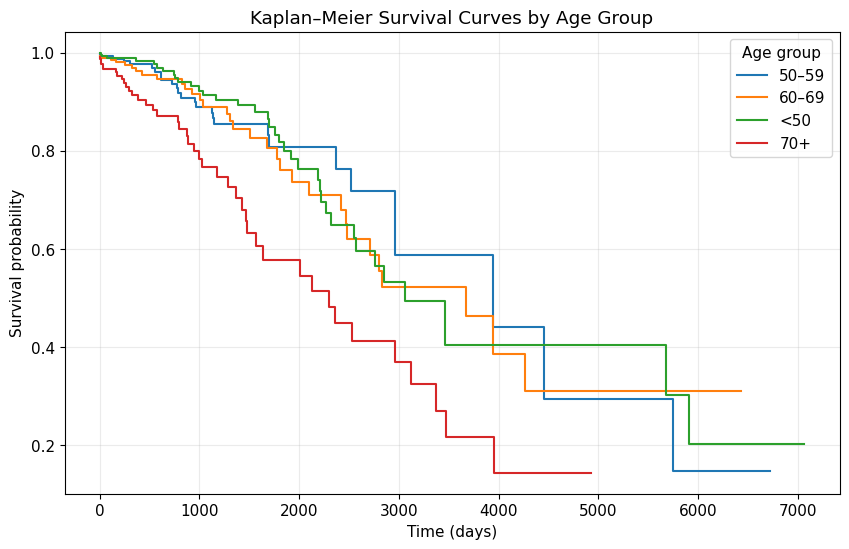

In [7]:
# %% Question 2 — Age and survival (Cox model)

from lifelines import CoxPHFitter
import pandas as pd

# Copy dataset
df_age = df.copy()

# Keep relevant columns
df_age = df_age[[
    "survival_time_days",
    "event",
    "age_at_diagnosis_years"
]].dropna().copy()

# Ensure correct types
df_age["event"] = df_age["event"].astype(int)
df_age["age_at_diagnosis_years"] = pd.to_numeric(df_age["age_at_diagnosis_years"], errors="coerce")

# Fit Cox model
cph_age = CoxPHFitter()
cph_age.fit(df_age, duration_col="survival_time_days", event_col="event")

print("\nCox model for age:")
cph_age.print_summary()

#====================================================================

# %% Kaplan–Meier by age groups (visualization)

from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt
import numpy as np

df_age_plot = df.copy()

# Create age groups
df_age_plot["age_group"] = pd.cut(
    df_age_plot["age_at_diagnosis_years"],
    bins=[0, 49, 59, 69, np.inf],
    labels=["<50", "50–59", "60–69", "70+"]
)

df_age_plot = df_age_plot.dropna(subset=["age_group", "survival_time_days", "event"])

kmf = KaplanMeierFitter()
plt.figure(figsize=(10, 6))

for group in df_age_plot["age_group"].unique():
    mask = df_age_plot["age_group"] == group
    kmf.fit(
        df_age_plot.loc[mask, "survival_time_days"],
        event_observed=df_age_plot.loc[mask, "event"],
        label=str(group)
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Kaplan–Meier Survival Curves by Age Group")
plt.xlabel("Time (days)")
plt.ylabel("Survival probability")
plt.legend(title="Age group")
plt.show()

## Question 3: Are pharmaceutical (drug) therapy and radiation therapy associated with survival outcomes in breast cancer patients?

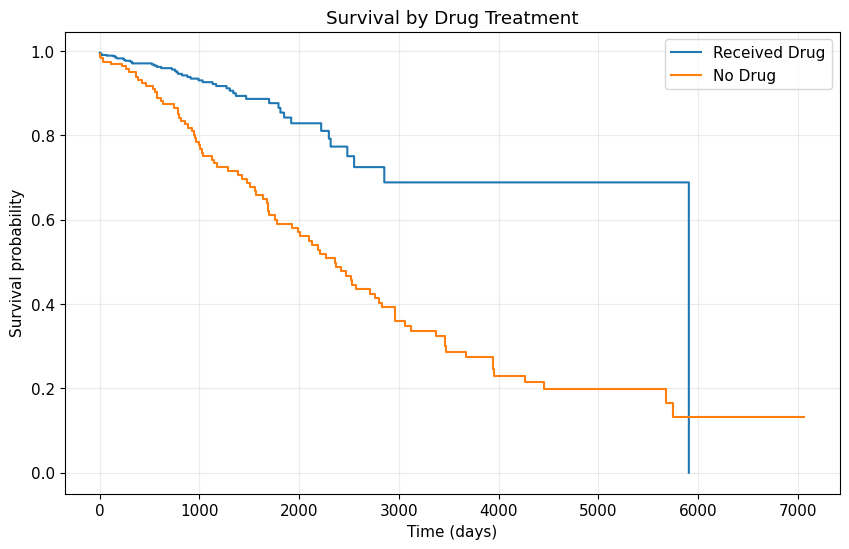


Log-rank (Drug):
   test_statistic             p   -log2(p)
0       35.453762  2.611774e-09  28.512323


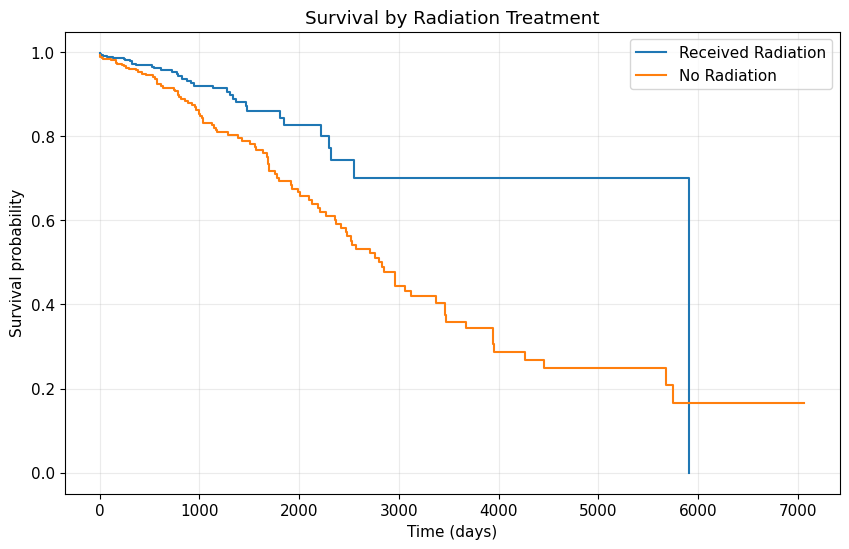


Log-rank (Radiation):
   test_statistic         p   -log2(p)
0       12.166222  0.000487  11.004893

Cox model (treatment):


<lifelines.CoxPHFitter: fitted with 1095 total observations, 955 right-censored observations>
             duration col = 'survival_time_days'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1095
number of events observed = 140
   partial log-likelihood = -730.68
         time fit was run = 2026-04-18 15:46:05 UTC

---
                            coef  exp(coef)   se(coef)   coef lower 95%   coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%
covariate                                                                                                                         
received_drug_record       -1.05       0.35       0.24            -1.51            -0.58                 0.22                 0.56
received_radiation_record  -0.04       0.96       0.25            -0.53             0.46                 0.59                 1.59

                            cmp to     z      p   -log2(p)
covariate                                                 
received_drug_record          0.00 -4.43 <0.005      16.69
received_radiation_record     0.00 -0.15   0.88       0.18
---
Concordance = 0.62
Partial AIC = 1465.36
log-likelihood ratio test = 34.22 on 2 df
-log2(p) of ll-ratio test = 24.69

In [8]:
# %% Question 3 — Treatment effects

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt
import pandas as pd

df_treat = df.copy()

# Ensure correct types
df_treat["event"] = df_treat["event"].astype(int)

# -----------------------------
# Kaplan–Meier: Drug
# -----------------------------
kmf = KaplanMeierFitter()
plt.figure(figsize=(10, 6))

for val, label in [(1, "Received Drug"), (0, "No Drug")]:
    mask = df_treat["received_drug_record"] == val
    kmf.fit(
        df_treat.loc[mask, "survival_time_days"],
        event_observed=df_treat.loc[mask, "event"],
        label=label
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Survival by Drug Treatment")
plt.xlabel("Time (days)")
plt.ylabel("Survival probability")
plt.legend()
plt.show()

# Log-rank test (drug)
lr_drug = logrank_test(
    df_treat.loc[df_treat["received_drug_record"] == 1, "survival_time_days"],
    df_treat.loc[df_treat["received_drug_record"] == 0, "survival_time_days"],
    event_observed_A=df_treat.loc[df_treat["received_drug_record"] == 1, "event"],
    event_observed_B=df_treat.loc[df_treat["received_drug_record"] == 0, "event"]
)

print("\nLog-rank (Drug):")
print(lr_drug.summary)


# -----------------------------
# Kaplan–Meier: Radiation
# -----------------------------
plt.figure(figsize=(10, 6))

for val, label in [(1, "Received Radiation"), (0, "No Radiation")]:
    mask = df_treat["received_radiation_record"] == val
    kmf.fit(
        df_treat.loc[mask, "survival_time_days"],
        event_observed=df_treat.loc[mask, "event"],
        label=label
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Survival by Radiation Treatment")
plt.xlabel("Time (days)")
plt.ylabel("Survival probability")
plt.legend()
plt.show()

# Log-rank test (radiation)
lr_rad = logrank_test(
    df_treat.loc[df_treat["received_radiation_record"] == 1, "survival_time_days"],
    df_treat.loc[df_treat["received_radiation_record"] == 0, "survival_time_days"],
    event_observed_A=df_treat.loc[df_treat["received_radiation_record"] == 1, "event"],
    event_observed_B=df_treat.loc[df_treat["received_radiation_record"] == 0, "event"]
)

print("\nLog-rank (Radiation):")
print(lr_rad.summary)


# -----------------------------
# Cox model (both together)
# -----------------------------
cox_treat = df_treat[[
    "survival_time_days",
    "event",
    "received_drug_record",
    "received_radiation_record"
]].copy()

cph_treat = CoxPHFitter()
cph_treat.fit(cox_treat, duration_col="survival_time_days", event_col="event")

print("\nCox model (treatment):")
cph_treat.print_summary()

## Question 4: Do treatment effects differ between early-stage and late-stage disease?

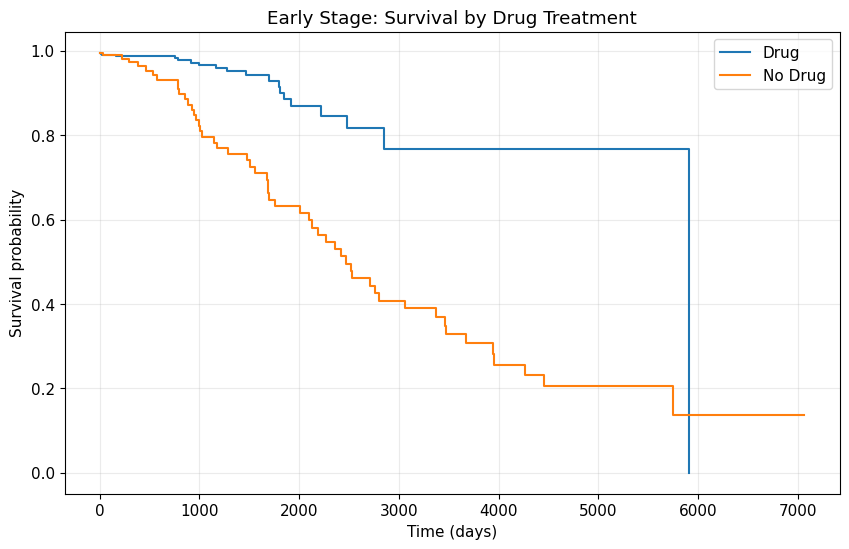

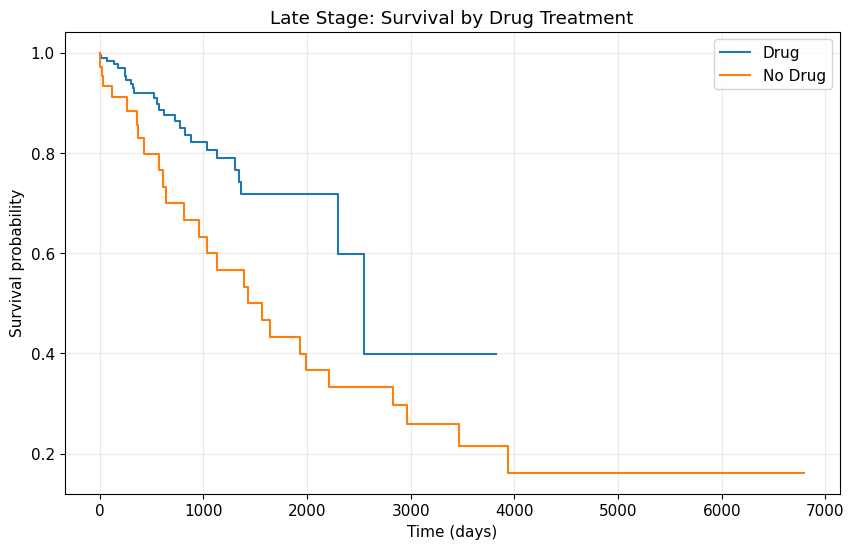

In [9]:
# %% Question 4 — Treatment effect by stage

from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt
import pandas as pd

df_q4 = df.copy()

# Create stage groups
df_q4["stage_binary"] = df_q4["stage_group"].replace({
    "Stage I": "Early",
    "Stage II": "Early",
    "Stage III": "Late",
    "Stage IV": "Late"
})

# Drop unknown stages
df_q4 = df_q4[df_q4["stage_binary"].isin(["Early", "Late"])].copy()

kmf = KaplanMeierFitter()

# -----------------------------
# Early stage — Drug
# -----------------------------
plt.figure(figsize=(10, 6))

for val, label in [(1, "Drug"), (0, "No Drug")]:
    mask = (df_q4["stage_binary"] == "Early") & (df_q4["received_drug_record"] == val)
    kmf.fit(
        df_q4.loc[mask, "survival_time_days"],
        event_observed=df_q4.loc[mask, "event"],
        label=label
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Early Stage: Survival by Drug Treatment")
plt.xlabel("Time (days)")
plt.ylabel("Survival probability")
plt.legend()
plt.show()
# -----------------------------
# Late stage — Drug
# -----------------------------
plt.figure(figsize=(10, 6))

for val, label in [(1, "Drug"), (0, "No Drug")]:
    mask = (df_q4["stage_binary"] == "Late") & (df_q4["received_drug_record"] == val)
    kmf.fit(
        df_q4.loc[mask, "survival_time_days"],
        event_observed=df_q4.loc[mask, "event"],
        label=label
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Late Stage: Survival by Drug Treatment")
plt.xlabel("Time (days)")
plt.ylabel("Survival probability")
plt.legend()
plt.show()

## Multivariable Survival Analysis: Identifying Independent Predictors of Survival

**Step 1: Preparing the dataset**

In [10]:
# %% Multivariable Cox Model — Data Preparation

from lifelines import CoxPHFitter
import pandas as pd

df_multi = df.copy()

# Drop unused columns
drop_cols = [
    "bcr_patient_barcode",
    "histological_type",  # using simplified version instead
]

df_multi = df_multi.drop(columns=[c for c in drop_cols if c in df_multi.columns])

# Use simplified histology
if "histological_type_simplified" in df_multi.columns:
    df_multi = df_multi.rename(columns={"histological_type_simplified": "histology"})

# Drop rows with missing survival info
df_multi = df_multi.dropna(subset=["survival_time_days", "event"])

# Ensure correct types
df_multi["event"] = df_multi["event"].astype(int)

**Step 2: Selecting variables**

In [11]:
# %% Select variables for model

model_vars = [
    "survival_time_days",
    "event",
    "age_at_diagnosis_years",
    "stage_group",
    "er_status_by_ihc",
    "pr_status_by_ihc",
    "her2_status_by_ihc",
    "received_drug_record",
    "received_radiation_record",
    "histology",
    "menopause_status"
]

df_model = df_multi[[c for c in model_vars if c in df_multi.columns]].copy()

**Step 3: Encoding categorical variables**

In [12]:
# %% One-hot encoding

categorical_cols = [
    "stage_group",
    "er_status_by_ihc",
    "pr_status_by_ihc",
    "her2_status_by_ihc",
    "histology",
    "menopause_status"
]

df_model = pd.get_dummies(
    df_model,
    columns=[c for c in categorical_cols if c in df_model.columns],
    drop_first=True
)

**Step 4: Fitting the Cox model**

In [13]:
# %% Fit Cox model

cph_multi = CoxPHFitter()

cph_multi.fit(
    df_model,
    duration_col="survival_time_days",
    event_col="event"
)

print("\nMultivariable Cox Model Results:")
cph_multi.print_summary()


Multivariable Cox Model Results:


<lifelines.CoxPHFitter: fitted with 1095 total observations, 955 right-censored observations>
             duration col = 'survival_time_days'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1095
number of events observed = 140
   partial log-likelihood = -684.79
         time fit was run = 2026-04-18 15:46:38 UTC

---
                                                                                                                coef  exp(coef)   se(coef)   coef lower 95%   coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%
covariate                                                                                                                                                                                                             
age_at_diagnosis_years                                                                                          0.02       1.02       0.01             0.00             0.04                 1.00                 1.04
received_drug_record                                                                                           -1.02       0.36       0.28            -1.57            -0.46                 0.21                 0.63
received_radiation_record                                                                                       0.00       1.00       0.27            -0.53             0.54                 0.59                 1.72
stage_group_Stage II                                                                                            0.42       1.53       0.30            -0.16             1.00                 0.86                 2.72
stage_group_Stage III                                                                                           1.24       3.47       0.31             0.63             1.86                 1.88                 6.41
stage_group_Stage IV                                                                                            2.13       8.46       0.39             1.37             2.90                 3.94                18.14
stage_group_Unknown                                                                                             0.98       2.67       0.42             0.15             1.81                 1.17                 6.10
er_status_by_ihc_Unknown                                                                                       18.60   1.20e+08  137979.30       -270415.85        270453.05                 0.00                  inf
er_status_by_ihc_Yes                                                                                           -0.15       0.86       0.30            -0.74             0.44                 0.48                 1.55
er_status_by_ihc_indeterminate                                                                                  1.35       3.85       0.78            -0.17             2.87                 0.84                17.67
pr_status_by_ihc_Unknown                                                                                      -17.50       0.00  137979.30       -270451.95        270416.95                 0.00                  inf
pr_status_by_ihc_Yes                                                                                           -0.34       0.71       0.28            -0.89             0.21                 0.41                 1.24
pr_status_by_ihc_indeterminate                                                                                  0.43       1.54       1.05            -1.62             2.48                 0.20                11.97
her2_status_by_ihc_Unknown                                                                                     -0.39       0.68       0.26            -0.89             0.12                 0.41                 1.13
her2_status_by_ihc_Yes                                                                                          0.12       1.12       0.28            -0.44             0.67               

**Forest plot for the multivariable Cox model**

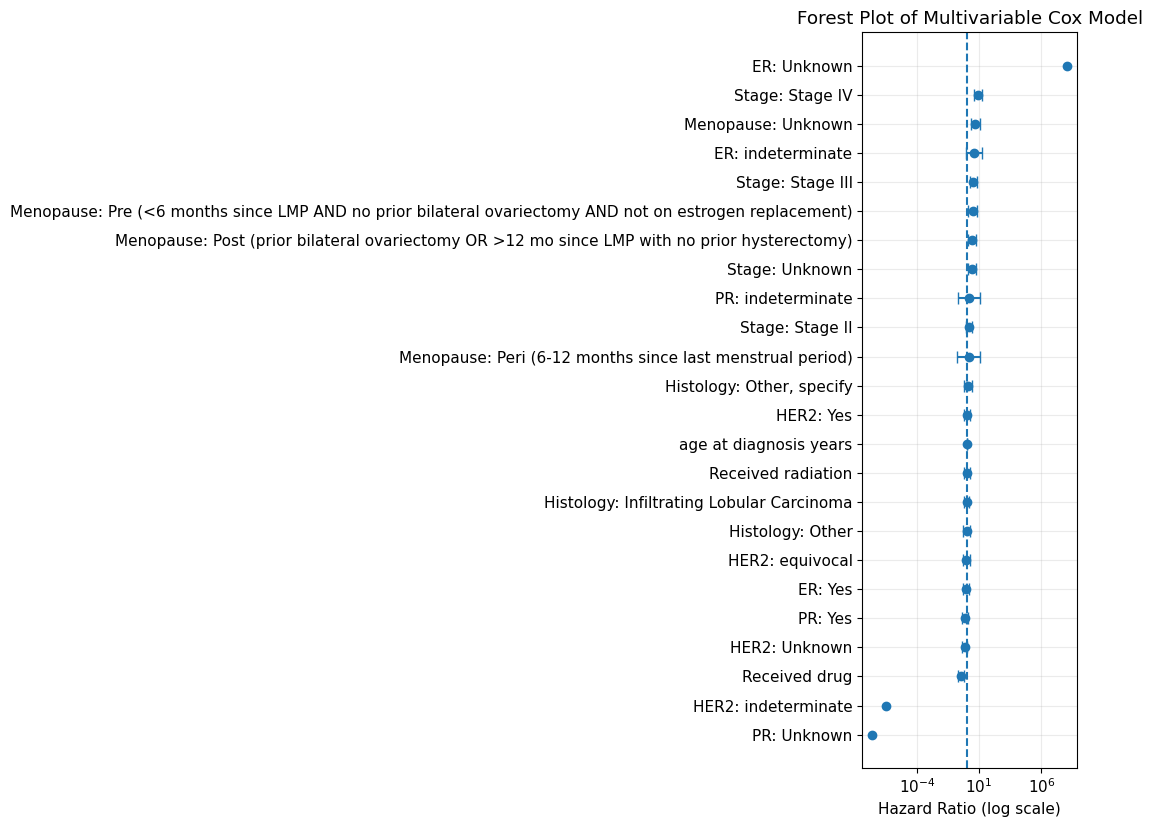

In [14]:
# %% Visualization 1: Improved forest plot for multivariable Cox model

import matplotlib.pyplot as plt
import pandas as pd

# Pull model summary
summary = cph_multi.summary.copy().reset_index()
summary = summary.rename(columns={summary.columns[0]: "variable"})

# Helper to shorten long variable names
def clean_name(name: str) -> str:
    name = str(name)
    name = name.replace("stage_group_", "Stage: ")
    name = name.replace("er_status_by_ihc_", "ER: ")
    name = name.replace("pr_status_by_ihc_", "PR: ")
    name = name.replace("her2_status_by_ihc_", "HER2: ")
    name = name.replace("menopause_status_", "Menopause: ")
    name = name.replace("histology_", "Histology: ")
    name = name.replace("_was_missing", " missing")
    name = name.replace("received_drug_record", "Received drug")
    name = name.replace("received_radiation_record", "Received radiation")
    name = name.replace("_", " ")
    return name

summary["clean_variable"] = summary["variable"].apply(clean_name)

# Keep only what is needed
plot_df = summary[[
    "clean_variable",
    "exp(coef)",
    "exp(coef) lower 95%",
    "exp(coef) upper 95%",
    "p"
]].copy()

# Sort by hazard ratio
plot_df = plot_df.sort_values("exp(coef)")

# Create figure
fig1, ax1 = plt.subplots(figsize=(11, max(6, len(plot_df) * 0.35)))

ax1.errorbar(
    x=plot_df["exp(coef)"],
    y=plot_df["clean_variable"],
    xerr=[
        plot_df["exp(coef)"] - plot_df["exp(coef) lower 95%"],
        plot_df["exp(coef) upper 95%"] - plot_df["exp(coef)"]
    ],
    fmt="o",
    capsize=4
)

ax1.axvline(x=1, linestyle="--")
ax1.set_xscale("log")
ax1.set_xlabel("Hazard Ratio (log scale)")
ax1.set_ylabel("")
ax1.set_title("Forest Plot of Multivariable Cox Model")

plt.tight_layout()
plt.show()

**Variable importance plot for the multivariable Cox model**

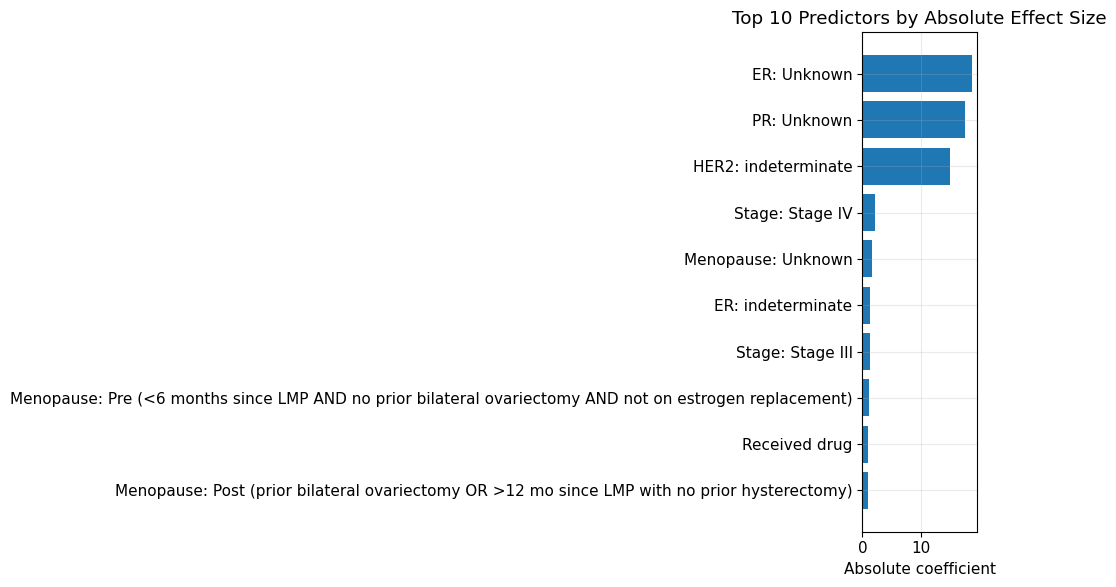

In [15]:
# %% Visualization 2: Top 10 variable importance plot

import matplotlib.pyplot as plt
import pandas as pd

# Pull model summary again
summary = cph_multi.summary.copy().reset_index()
summary = summary.rename(columns={summary.columns[0]: "variable"})

# Reuse the same label-cleaning helper from the first block
summary["clean_variable"] = summary["variable"].apply(clean_name)

# Use absolute coefficient size as a simple importance measure
summary["importance"] = summary["coef"].abs()

# Keep the top 10 most important predictors
top_vars = summary.sort_values("importance", ascending=False).head(10)

# Reverse order so the largest appears at the top of the bar chart
top_vars = top_vars.sort_values("importance", ascending=True)

# Create figure
fig2, ax2 = plt.subplots(figsize=(10, 6))

ax2.barh(top_vars["clean_variable"], top_vars["importance"])
ax2.set_xlabel("Absolute coefficient")
ax2.set_ylabel("")
ax2.set_title("Top 10 Predictors by Absolute Effect Size")

plt.tight_layout()
plt.show()

## Model Refinement and Comparison: Clean Multivariable Cox Model

In [16]:
# %% Clean Multivariable Cox Model + Comparison

from lifelines import CoxPHFitter
import pandas as pd

# --------------------------------------------------
# STEP 1: Create a copy of the model dataset
# --------------------------------------------------
df_clean = df_model.copy()

# --------------------------------------------------
# STEP 2: Remove problematic / unstable variables
# These include:
# - "Unknown" categories
# - "indeterminate" categories
# These caused extreme / unreliable estimates earlier
# --------------------------------------------------
cols_to_drop = [
    c for c in df_clean.columns
    if ("Unknown" in c) or ("indeterminate" in c)
]

print("Dropping unstable columns:")
print(cols_to_drop)

df_clean = df_clean.drop(columns=cols_to_drop)

# --------------------------------------------------
# STEP 3: Fit the CLEAN Cox model
# --------------------------------------------------
cph_clean = CoxPHFitter()

cph_clean.fit(
    df_clean,
    duration_col="survival_time_days",
    event_col="event"
)

print("\nClean Cox Model Results:")
cph_clean.print_summary()

# --------------------------------------------------
# STEP 4: Compare model performance
# We use concordance index (higher is better)
# --------------------------------------------------
print("\nModel Comparison:")
print("Original model concordance:", round(cph_multi.concordance_index_, 3))
print("Clean model concordance:", round(cph_clean.concordance_index_, 3))

# --------------------------------------------------
# STEP 5: Compare number of variables
# --------------------------------------------------
print("\nNumber of variables:")
print("Original model:", df_model.shape[1] - 2)  # excluding survival + event
print("Clean model:", df_clean.shape[1] - 2)

Dropping unstable columns:
['stage_group_Unknown', 'er_status_by_ihc_Unknown', 'er_status_by_ihc_indeterminate', 'pr_status_by_ihc_Unknown', 'pr_status_by_ihc_indeterminate', 'her2_status_by_ihc_Unknown', 'her2_status_by_ihc_indeterminate', 'menopause_status_Unknown']

Clean Cox Model Results:


<lifelines.CoxPHFitter: fitted with 1095 total observations, 955 right-censored observations>
             duration col = 'survival_time_days'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1095
number of events observed = 140
   partial log-likelihood = -702.02
         time fit was run = 2026-04-18 15:48:00 UTC

---
                                                                                                                coef  exp(coef)   se(coef)   coef lower 95%   coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%
covariate                                                                                                                                                                                                             
age_at_diagnosis_years                                                                                          0.03       1.03       0.01             0.01             0.05                 1.01                 1.05
received_drug_record                                                                                           -0.87       0.42       0.27            -1.40            -0.34                 0.25                 0.71
received_radiation_record                                                                                      -0.07       0.93       0.27            -0.60             0.46                 0.55                 1.58
stage_group_Stage II                                                                                            0.24       1.27       0.24            -0.23             0.71                 0.79                 2.04
stage_group_Stage III                                                                                           0.93       2.53       0.26             0.41             1.44                 1.51                 4.22
stage_group_Stage IV                                                                                            1.72       5.60       0.35             1.03             2.42                 2.80                11.20
er_status_by_ihc_Yes                                                                                           -0.31       0.73       0.29            -0.88             0.26                 0.42                 1.29
pr_status_by_ihc_Yes                                                                                           -0.35       0.71       0.28            -0.89             0.20                 0.41                 1.22
her2_status_by_ihc_Yes                                                                                          0.43       1.54       0.25            -0.06             0.93                 0.94                 2.53
her2_status_by_ihc_equivocal                                                                                    0.07       1.07       0.31            -0.53             0.67                 0.59                 1.95
histology_Infiltrating Lobular Carcinoma                                                                       -0.01       0.99       0.26            -0.52             0.50                 0.59                 1.65
histology_Other                                                                                                 0.06       1.06       0.33            -0.59             0.71                 0.55                 2.03
histology_Other, specify                                                                                       -0.01       0.99       0.38            -0.76             0.73                 0.47                 2.08
menopause_status_Peri (6-12 months since last menstrual period)                                                -0.69       0.50       1.03            -2.71             1.33                 0.07                 3.80
menopause_status_Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy)             -0.08       0.92       0.27            -0.61             0.44               


Model Comparison:
Original model concordance: 0.781
Clean model concordance: 0.762

Number of variables:
Original model: 24
Clean model: 16


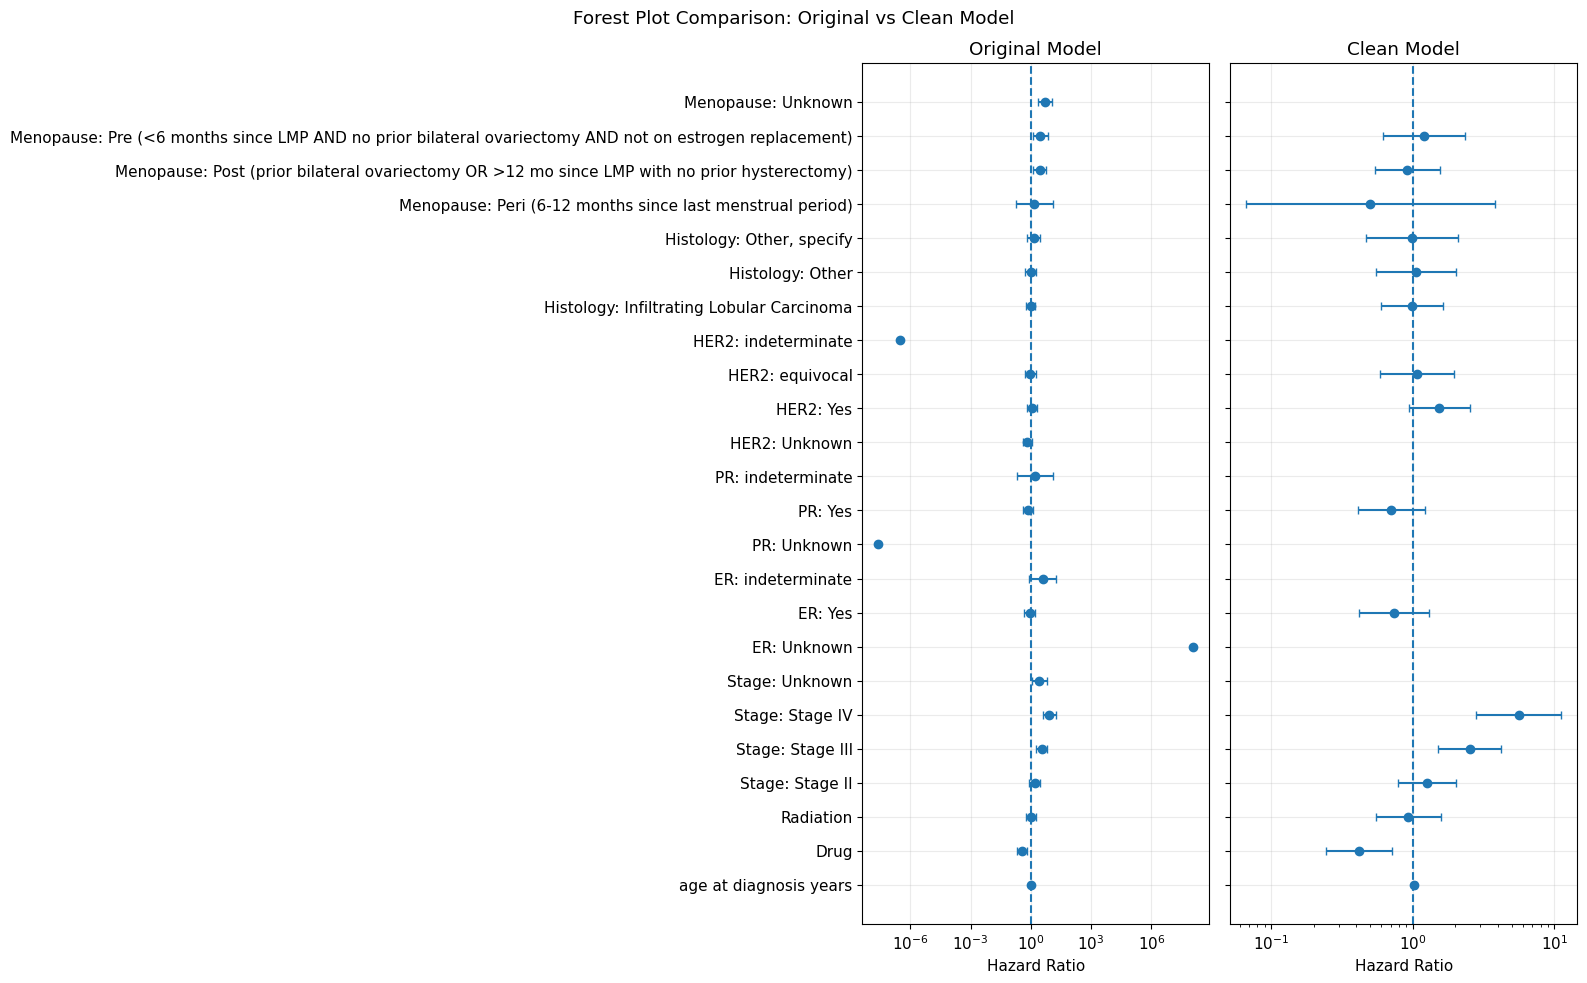

In [25]:
# %% Forest Plot Comparison: Original vs Clean

import matplotlib.pyplot as plt
import pandas as pd

# --- Extract summaries ---
orig = cph_multi.summary.copy().reset_index()
orig = orig.rename(columns={orig.columns[0]: "variable"})

clean = cph_clean.summary.copy().reset_index()
clean = clean.rename(columns={clean.columns[0]: "variable"})

# --- Clean variable names (same function for both) ---
def clean_name(name):
    name = str(name)
    name = name.replace("stage_group_", "Stage: ")
    name = name.replace("er_status_by_ihc_", "ER: ")
    name = name.replace("pr_status_by_ihc_", "PR: ")
    name = name.replace("her2_status_by_ihc_", "HER2: ")
    name = name.replace("menopause_status_", "Menopause: ")
    name = name.replace("histology_", "Histology: ")
    name = name.replace("received_drug_record", "Drug")
    name = name.replace("received_radiation_record", "Radiation")
    name = name.replace("_", " ")
    return name

orig["label"] = orig["variable"].apply(clean_name)
clean["label"] = clean["variable"].apply(clean_name)

# --- Create figure with 2 panels ---
fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharey=True)

# --- Original model plot ---
axes[0].errorbar(
    x=orig["exp(coef)"],
    y=orig["label"],
    xerr=[
        orig["exp(coef)"] - orig["exp(coef) lower 95%"],
        orig["exp(coef) upper 95%"] - orig["exp(coef)"]
    ],
    fmt="o",
    capsize=3
)

axes[0].axvline(x=1, linestyle="--")
axes[0].set_xscale("log")
axes[0].set_title("Original Model")
axes[0].set_xlabel("Hazard Ratio")

# --- Clean model plot ---
axes[1].errorbar(
    x=clean["exp(coef)"],
    y=clean["label"],
    xerr=[
        clean["exp(coef)"] - clean["exp(coef) lower 95%"],
        clean["exp(coef) upper 95%"] - clean["exp(coef)"]
    ],
    fmt="o",
    capsize=3
)

axes[1].axvline(x=1, linestyle="--")
axes[1].set_xscale("log")
axes[1].set_title("Clean Model")
axes[1].set_xlabel("Hazard Ratio")

plt.suptitle("Forest Plot Comparison: Original vs Clean Model")
plt.tight_layout()
plt.show()

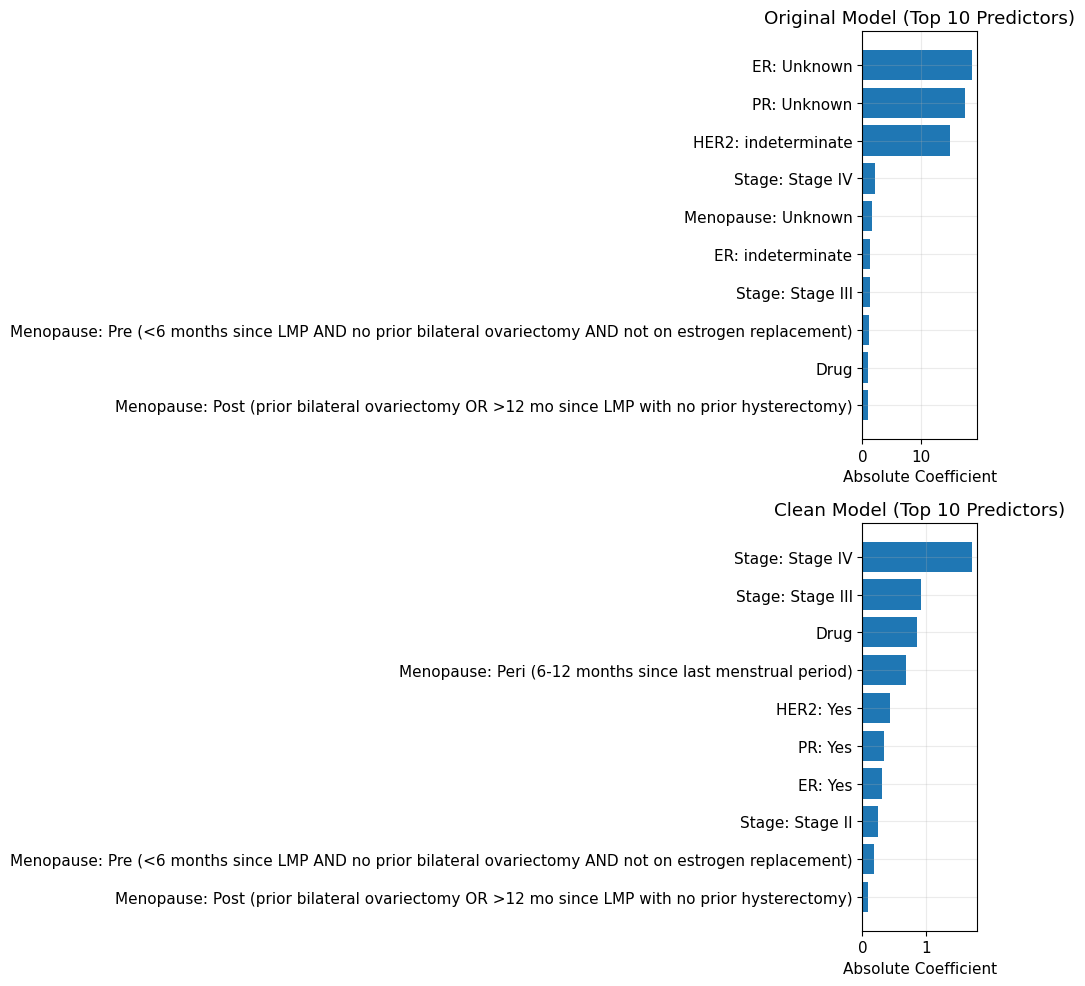

In [27]:
# %% Effect Size Comparison (Stacked vertically)

import matplotlib.pyplot as plt
import pandas as pd

# --- Compute importance ---
orig["importance"] = orig["coef"].abs()
clean["importance"] = clean["coef"].abs()

# --- Keep top 10 variables ---
orig_top = orig.sort_values("importance", ascending=False).head(10)
clean_top = clean.sort_values("importance", ascending=False).head(10)

# --- Sort for plotting (small → large for barh)
orig_top = orig_top.sort_values("importance")
clean_top = clean_top.sort_values("importance")

# --- Create stacked plots (2 rows, 1 column)
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# --- Original model (top)
axes[0].barh(orig_top["label"], orig_top["importance"])
axes[0].set_title("Original Model (Top 10 Predictors)")
axes[0].set_xlabel("Absolute Coefficient")
axes[0].set_ylabel("")

# --- Clean model (bottom)
axes[1].barh(clean_top["label"], clean_top["importance"])
axes[1].set_title("Clean Model (Top 10 Predictors)")
axes[1].set_xlabel("Absolute Coefficient")
axes[1].set_ylabel("")

# Adjust spacing
plt.tight_layout()

plt.show()

## Question 5:Do biomarker variables (ER, PR, HER2) affect survival outcomes?

**First: Estrogen Receptor**

ER distribution:
er_status_by_ihc
Yes    807
No     238
Name: count, dtype: int64


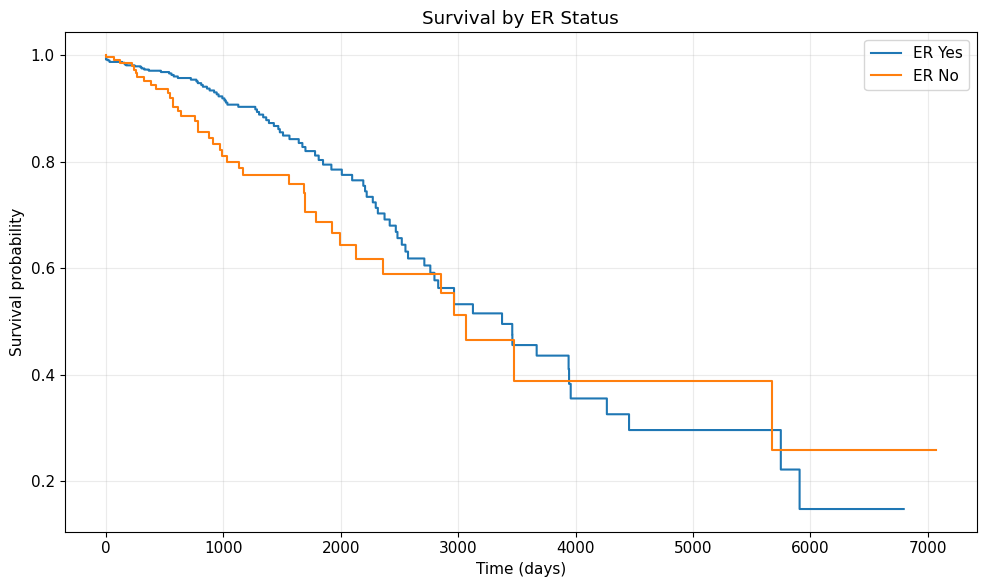


Log-rank test (ER):
   test_statistic         p  -log2(p)
0         2.94623  0.086078  3.538209


<Figure size 1000x600 with 0 Axes>

In [33]:
# %% Question 5 — ER status and survival

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt

# --------------------------------------------------
# STEP 1: Copy dataset
# --------------------------------------------------
df_er = df.copy()

# --------------------------------------------------
# STEP 2: Keep only valid ER categories
# Remove "Unknown" and "indeterminate" for clarity
# --------------------------------------------------
df_er = df_er[df_er["er_status_by_ihc"].isin(["Yes", "No"])].copy()

print("ER distribution:")
print(df_er["er_status_by_ihc"].value_counts())

# --------------------------------------------------
# STEP 3: Kaplan–Meier curves
# --------------------------------------------------
kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for val in ["Yes", "No"]:
    mask = df_er["er_status_by_ihc"] == val
    kmf.fit(
        durations=df_er.loc[mask, "survival_time_days"],
        event_observed=df_er.loc[mask, "event"],
        label=f"ER {val}"
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Survival by ER Status")
plt.xlabel("Time (days)")
plt.ylabel("Survival probability")
plt.legend()
plt.tight_layout()
plt.show()
# --------------------------------------------------
# STEP 4: Log-rank test
# --------------------------------------------------
lr_er = logrank_test(
    df_er.loc[df_er["er_status_by_ihc"] == "Yes", "survival_time_days"],
    df_er.loc[df_er["er_status_by_ihc"] == "No", "survival_time_days"],
    event_observed_A=df_er.loc[df_er["er_status_by_ihc"] == "Yes", "event"],
    event_observed_B=df_er.loc[df_er["er_status_by_ihc"] == "No", "event"]
)

print("\nLog-rank test (ER):")
print(lr_er.summary)

**Second: Progesterone Receptor**

PR distribution:
pr_status_by_ihc
Yes    698
No     344
Name: count, dtype: int64


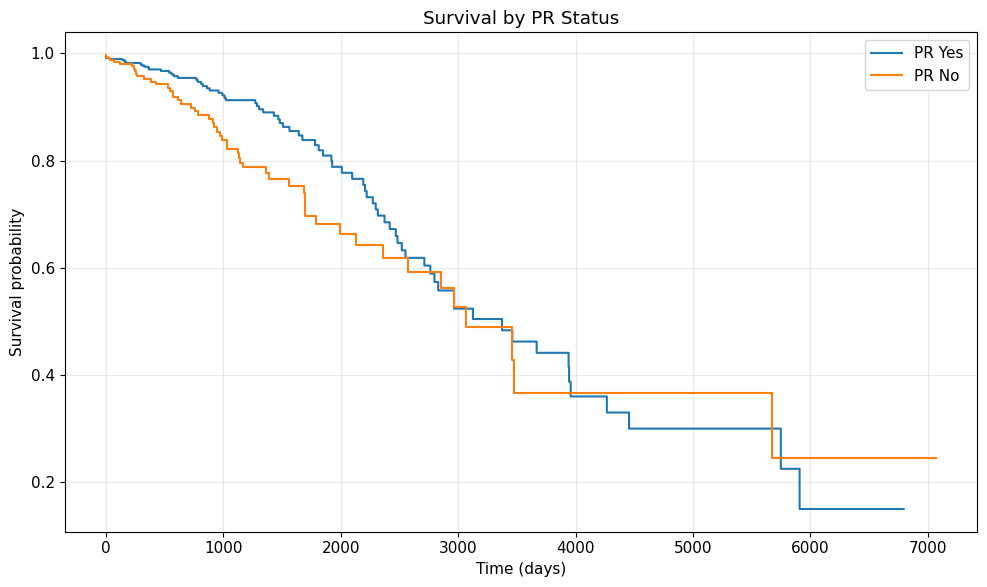


Log-rank test (PR):
   test_statistic         p  -log2(p)
0        3.702672  0.054325  4.202229


In [34]:
# %% Question 5 — PR status and survival

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt

# --------------------------------------------------
# STEP 1: Copy dataset
# --------------------------------------------------
df_pr = df.copy()

# --------------------------------------------------
# STEP 2: Keep only valid PR categories
# Remove "Unknown" and "indeterminate" for clarity
# --------------------------------------------------
df_pr = df_pr[df_pr["pr_status_by_ihc"].isin(["Yes", "No"])].copy()

print("PR distribution:")
print(df_pr["pr_status_by_ihc"].value_counts())

# --------------------------------------------------
# STEP 3: Kaplan–Meier curves
# --------------------------------------------------
kmf = KaplanMeierFitter()

fig_pr, ax_pr = plt.subplots(figsize=(10, 6))

for val in ["Yes", "No"]:
    mask = df_pr["pr_status_by_ihc"] == val
    kmf.fit(
        durations=df_pr.loc[mask, "survival_time_days"],
        event_observed=df_pr.loc[mask, "event"],
        label=f"PR {val}"
    )
    kmf.plot_survival_function(ci_show=False, ax=ax_pr)

ax_pr.set_title("Survival by PR Status")
ax_pr.set_xlabel("Time (days)")
ax_pr.set_ylabel("Survival probability")
ax_pr.legend()

plt.tight_layout()
fig_pr.savefig(OUT_DIR / "question5_pr_km_plot.png", dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# STEP 4: Log-rank test
# --------------------------------------------------
lr_pr = logrank_test(
    df_pr.loc[df_pr["pr_status_by_ihc"] == "Yes", "survival_time_days"],
    df_pr.loc[df_pr["pr_status_by_ihc"] == "No", "survival_time_days"],
    event_observed_A=df_pr.loc[df_pr["pr_status_by_ihc"] == "Yes", "event"],
    event_observed_B=df_pr.loc[df_pr["pr_status_by_ihc"] == "No", "event"]
)

print("\nLog-rank test (PR):")
print(lr_pr.summary)

**Third: HER2**

HER2 distribution:
her2_status_by_ihc
No     563
Yes    164
Name: count, dtype: int64


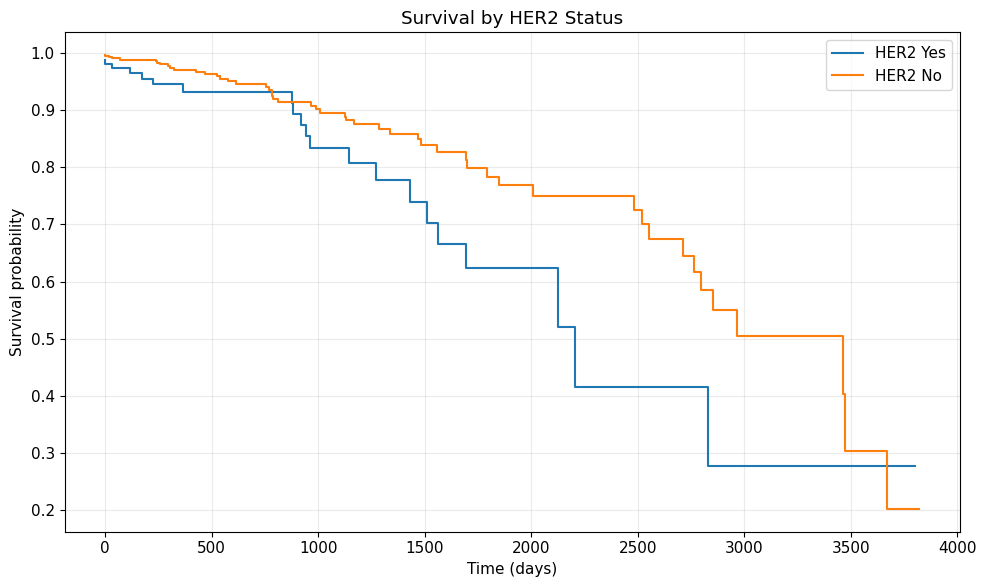


Log-rank test (HER2):
   test_statistic         p  -log2(p)
0        5.521002  0.018789   5.73393


In [35]:
# %% Question 5 — HER2 status and survival

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt

# --------------------------------------------------
# STEP 1: Copy dataset
# --------------------------------------------------
df_her2 = df.copy()

# --------------------------------------------------
# STEP 2: Keep only valid HER2 categories for a clean comparison
# Here we compare Yes vs No only
# --------------------------------------------------
df_her2 = df_her2[df_her2["her2_status_by_ihc"].isin(["Yes", "No"])].copy()

print("HER2 distribution:")
print(df_her2["her2_status_by_ihc"].value_counts())

# --------------------------------------------------
# STEP 3: Kaplan–Meier curves
# --------------------------------------------------
kmf = KaplanMeierFitter()

fig_her2, ax_her2 = plt.subplots(figsize=(10, 6))

for val in ["Yes", "No"]:
    mask = df_her2["her2_status_by_ihc"] == val
    kmf.fit(
        durations=df_her2.loc[mask, "survival_time_days"],
        event_observed=df_her2.loc[mask, "event"],
        label=f"HER2 {val}"
    )
    kmf.plot_survival_function(ci_show=False, ax=ax_her2)

ax_her2.set_title("Survival by HER2 Status")
ax_her2.set_xlabel("Time (days)")
ax_her2.set_ylabel("Survival probability")
ax_her2.legend()

plt.tight_layout()
fig_her2.savefig(OUT_DIR / "question5_her2_km_plot.png", dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# STEP 4: Log-rank test
# --------------------------------------------------
lr_her2 = logrank_test(
    df_her2.loc[df_her2["her2_status_by_ihc"] == "Yes", "survival_time_days"],
    df_her2.loc[df_her2["her2_status_by_ihc"] == "No", "survival_time_days"],
    event_observed_A=df_her2.loc[df_her2["her2_status_by_ihc"] == "Yes", "event"],
    event_observed_B=df_her2.loc[df_her2["her2_status_by_ihc"] == "No", "event"]
)

print("\nLog-rank test (HER2):")
print(lr_her2.summary)

## Risk Stratification Using the Multivariable Cox Model
## Can we classify patients into high-risk and low-risk groups based on the multivariable Cox model?



Risk group distribution:
risk_group
Low Risk     548
High Risk    547
Name: count, dtype: int64


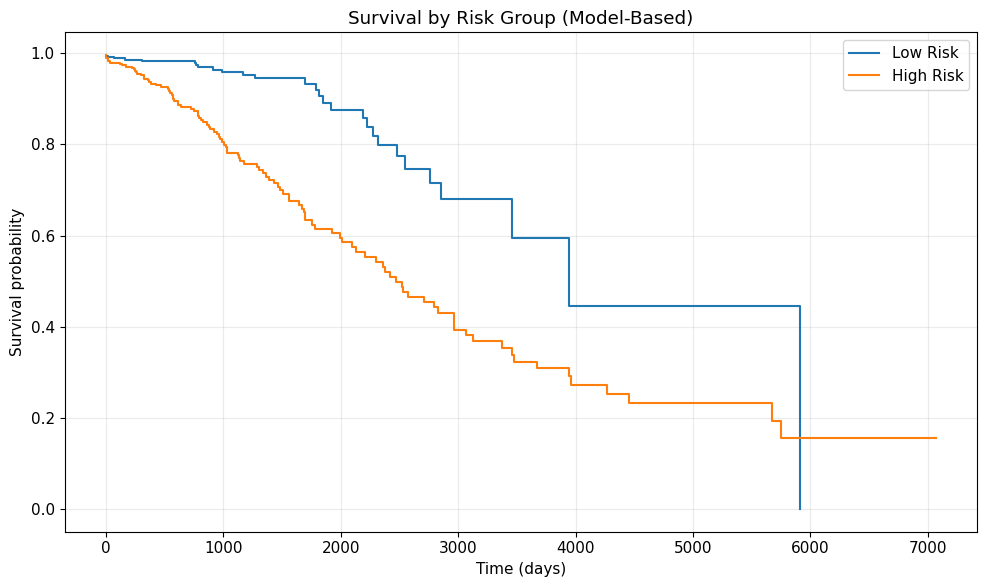


Log-rank test (Risk groups):
   test_statistic             p   -log2(p)
0       38.402338  5.756340e-10  30.694129


In [39]:
# %% Risk Group Analysis (Fixed version)

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt
import pandas as pd

# --------------------------------------------------
# STEP 1: Recreate CLEAN dataset (same as before)
# --------------------------------------------------
df_clean = df_model.copy()

# Drop unstable columns again
cols_to_drop = [
    c for c in df_clean.columns
    if ("Unknown" in c) or ("indeterminate" in c)
]

df_model_clean = df_clean.drop(columns=cols_to_drop).copy()

# --------------------------------------------------
# STEP 2: Get risk scores from CLEAN model
# --------------------------------------------------
risk_scores = cph_clean.predict_partial_hazard(df_model_clean)

# --------------------------------------------------
# STEP 3: Create risk groups (Low vs High)
# --------------------------------------------------
df_model_clean["risk_group"] = pd.qcut(
    risk_scores,
    q=2,
    labels=["Low Risk", "High Risk"]
)

print("\nRisk group distribution:")
print(df_model_clean["risk_group"].value_counts())

# --------------------------------------------------
# STEP 4: Kaplan–Meier plot
# --------------------------------------------------
kmf = KaplanMeierFitter()

fig_risk, ax_risk = plt.subplots(figsize=(10, 6))

for group in ["Low Risk", "High Risk"]:
    mask = df_model_clean["risk_group"] == group
    kmf.fit(
        durations=df_model_clean.loc[mask, "survival_time_days"],
        event_observed=df_model_clean.loc[mask, "event"],
        label=group
    )
    kmf.plot_survival_function(ci_show=False, ax=ax_risk)

ax_risk.set_title("Survival by Risk Group (Model-Based)")
ax_risk.set_xlabel("Time (days)")
ax_risk.set_ylabel("Survival probability")
ax_risk.legend()

plt.tight_layout()

# Save plot
fig_risk.savefig(
    OUT_DIR / "risk_group_km_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# STEP 5: Log-rank test
# --------------------------------------------------
low = df_model_clean[df_model_clean["risk_group"] == "Low Risk"]
high = df_model_clean[df_model_clean["risk_group"] == "High Risk"]

lr_risk = logrank_test(
    low["survival_time_days"],
    high["survival_time_days"],
    event_observed_A=low["event"],
    event_observed_B=high["event"]
)

print("\nLog-rank test (Risk groups):")
print(lr_risk.summary)